# Comparing git embeddings of native structures and generated ones

In [1]:
import os, sys
import json
import logging
from typing import *

import numpy as np
import pandas as pd
import umap
from matplotlib import pyplot as plt
import seaborn as sns

from foldingdiff import plotting

SAMPLED_GIT_FNAME = "/home/wukevin/projects/protdiff_results/generation-random-seed-reps/generation_seed_7344/sampled_pdb_git_scores.txt"
TEST_GIT_FNAME = "/home/wukevin/projects/protdiff_results/generation-random-seed-reps/data_splits/test_files.git"

PLOT_DIR = os.path.join(plotting.PLOT_DIR, "git_umap")
assert os.path.isdir(PLOT_DIR)

In [2]:
sampled_metadata_df = pd.read_csv(
    "/home/wukevin/projects/protdiff_results/generation-random-seed-reps/generation_seed_7344/sctm_scores_proteinmpnn_tm_scores.csv",
    index_col=1,
).drop(columns=["Unnamed: 0"])
sampled_metadata_df.head()

,scTM,max training TM,length_int,alpha_counts,beta_counts,scTM best match,max training TM structure,length,designable
id,,,,,,,,,
generated_202,0.39745,0.46674,70,1,3,omegafold_predictions_proteinmpnn/generated_20...,/home/wukevin/projects/protdiff/data/cath/domp...,short ($\leq 70$ aa),False
generated_414,0.36039,0.46756,91,2,2,omegafold_predictions_proteinmpnn/generated_41...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False
generated_309,0.49600,0.60337,80,4,0,omegafold_predictions_proteinmpnn/generated_30...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False
generated_529,0.29100,0.36524,102,0,6,omegafold_predictions_proteinmpnn/generated_52...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False
generated_194,0.42942,0.47160,69,3,2,omegafold_predictions_proteinmpnn/generated_19...,/home/wukevin/projects/protdiff/data/cath/domp...,short ($\leq 70$ aa),False


In [3]:
def read_git(fname: str, min_length: int = 0, max_length: int = 0, index_name_func: Optional[Callable] = None) -> pd.DataFrame:
    """Read the embedding in the given git file"""
    retval = pd.read_csv(fname, index_col=0, sep=" ", header=None)
    retval.dropna(axis=1, how="all", inplace=True)
    # retval.drop(columns=[2], inplace=True)
    retval.columns = ['length'] + [f'git{i}' for i in range(1, 32)]

    if max_length > 0:
        retval = retval[retval['length'] <= max_length]
    if min_length > 0:
        retval = retval[retval['length'] >= min_length]

    if index_name_func is not None:
        retval.index = [index_name_func(f) for f in retval.index]
    
    return retval

test_git_values = read_git(
    TEST_GIT_FNAME,
    max_length=128,
    min_length=50,
    index_name_func=lambda x: "test_" + os.path.basename(x).split('.')[0]
).drop(columns=['length'])
test_git_values

,git1,git2,git3,git4,git5,git6,git7,git8,git9,git10,...,git22,git23,git24,git25,git26,git27,git28,git29,git30,git31
test_4liqE05,88.7008,-7.0795,-67.4595,175.9496,44.9703,152.2140,-56.9205,-45.9189,111.5494,-59.5553,...,-19.3715,6.3347,7.7099,-14.5269,-18.1952,-18.3577,-8.1440,13.2581,-18.5801,31.6878
test_4it4A02,85.9557,17.1122,15.3303,39.9423,-84.9125,32.9047,16.9357,37.2867,22.7621,14.7175,...,1.4672,5.3917,6.3819,12.8328,-8.8636,1.2247,-10.4796,3.7918,8.6775,7.2923
test_2ma6A00,75.2265,-26.9872,-50.1646,111.9611,-3.5762,100.1624,-14.0573,-45.8147,97.2583,-33.6637,...,1.1521,-5.2552,-6.6538,-0.4398,-25.9866,16.8555,13.1041,11.4870,-16.5445,8.5703
test_4xvhA01,90.7239,-132.6650,-54.6832,158.1341,36.9628,142.8357,-59.9838,-38.7119,101.8756,-39.1888,...,13.0999,29.2185,-11.8138,23.1287,-13.9015,5.1094,-19.7386,1.2397,0.0512,4.4938
test_1oxjA02,91.2857,14.6940,22.2869,56.9435,-60.4322,40.7287,22.5295,43.4806,35.9202,19.1511,...,6.8592,7.3778,6.9026,9.0953,-10.6689,6.4309,-3.1305,3.8776,1.3234,8.5448
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
test_1jb3A00,96.0569,186.2827,-3.4291,154.4794,44.1466,142.2261,-83.6292,-25.8129,100.0151,-42.5064,...,-14.5449,27.9511,2.8253,-22.9834,12.9703,-19.0574,-13.0981,8.9363,14.6129,14.7139
test_1dgjA01,80.2302,-44.3893,-48.8186,109.3161,-5.9504,110.1025,-28.7198,-33.6970,89.5622,-17.4990,...,-10.7486,-7.9609,2.7241,-0.0456,-5.4084,-2.7517,7.6460,4.4186,-0.9874,9.2385
test_4ak2A01,93.4665,48.9853,-14.4148,143.0355,29.1794,123.7964,18.3892,-25.7694,96.9449,-39.0472,...,0.1846,3.7016,-8.5610,-8.3723,10.5023,3.1270,9.0585,-2.9710,-5.1623,7.2621
test_4hj1C03,86.5808,73.1550,39.7509,205.6640,53.9248,162.1326,34.3389,-10.3743,123.9065,-46.1911,...,4.2163,-4.7766,-10.3416,9.3461,7.0049,3.5938,6.1094,8.3395,-14.3631,-10.1121


In [4]:
with open("/home/wukevin/projects/protdiff_results/generation-random-seed-reps/generation_seed_7344/ss_cooccurrence_test.json") as source:
    test_metadata = json.load(source)
test_metadata_df = pd.DataFrame(
    -1,
    index=test_git_values.index,
    columns=["alpha_counts", "beta_counts", ]
)
for key, pair in test_metadata.items():
    idx = f"test_{key}"
    if idx in test_metadata_df.index:
        test_metadata_df.loc[idx, "alpha_counts"] = pair[0]
        test_metadata_df.loc[idx, "beta_counts"] = pair[1]
assert not np.any(test_metadata_df == -1)  # No unfilled values
test_metadata_df

,alpha_counts,beta_counts
test_4liqE05,0,5
test_4it4A02,3,0
test_2ma6A00,1,0
test_4xvhA01,0,4
test_1oxjA02,5,0
...,...,...
test_1jb3A00,3,6
test_1dgjA01,1,1
test_4ak2A01,0,5
test_4hj1C03,0,8


In [5]:
sampled_git_values = read_git(
    SAMPLED_GIT_FNAME,
    max_length=128,
    index_name_func=lambda x: os.path.basename(x).split('.')[0]    
).drop(columns=['length'])
sampled_git_values

,git1,git2,git3,git4,git5,git6,git7,git8,git9,git10,...,git22,git23,git24,git25,git26,git27,git28,git29,git30,git31
generated_141,76.4400,3.8453,27.7331,95.9754,-19.5961,99.5244,23.3804,-24.8226,62.0038,-41.5870,...,5.9730,19.0066,-31.9792,19.6185,-1.5758,9.2981,13.1677,7.0275,-18.2099,-8.5431
generated_78,73.5449,16.3872,32.2376,59.7064,-54.9966,43.9128,15.5008,39.0500,44.0162,11.6113,...,10.1222,4.4595,0.9935,3.9819,-6.1802,5.3006,1.8850,-3.3904,2.4627,-1.1261
generated_317,82.6842,-14.5293,-3.3797,38.6942,-80.6911,32.2620,-14.2275,-27.1740,33.5408,-11.3089,...,-9.7897,-2.3585,-5.5974,-4.5933,1.3531,-4.1334,8.8174,-1.9603,-4.0869,1.1670
generated_777,96.0569,28.5094,6.2355,42.0266,-55.5323,32.3201,10.4040,12.6984,36.1285,-0.2309,...,-2.2745,11.1458,-24.6993,-12.2879,12.3937,-10.6704,8.9478,-3.2531,-4.9211,10.7228
generated_739,95.0377,-28.0400,1.7799,87.0122,-22.4641,60.8103,-38.1831,-11.8388,58.7658,-1.4970,...,6.4769,-4.9645,-15.4264,1.3001,-2.1385,7.9160,-2.7347,30.5249,-2.1616,5.5616
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
generated_412,85.9557,-9.5015,-7.6106,45.2029,-68.4553,44.3092,3.4334,6.8629,39.5239,7.4617,...,3.8797,1.0913,-1.2945,0.5016,7.3066,-0.3257,-2.9291,-3.5356,-2.5669,7.1494
generated_469,87.5020,11.9892,-0.0977,41.6783,-74.8897,31.5412,10.8185,19.2714,36.1626,7.4669,...,6.8933,3.7119,3.3838,-2.5662,4.4806,2.1716,-4.3140,1.9232,0.1786,-1.2993
generated_352,84.0234,96.8247,-41.3305,119.6608,3.4791,118.7693,-55.8818,-24.3871,88.4819,-40.8572,...,-31.4139,-14.4974,-14.6263,82.1354,-30.0520,27.0873,-16.6189,22.7924,-18.3259,0.2716
generated_403,85.6396,33.3539,5.7698,51.1711,-61.1415,41.0021,33.2039,44.9342,47.3677,10.8915,...,-9.2763,5.9147,12.2056,-3.3280,18.8644,3.2696,-3.4828,-8.9197,-36.8232,-10.3090


# Plots of sampled only

In [6]:
SEED = int(
    float.fromhex("2254616977616e2069732061206672656520636f756e74727922") % 10000
)

def umap_embed(values, seed: int = SEED):
    return pd.DataFrame(
        umap.UMAP(random_state=seed).fit_transform(values),
        index=values.index if isinstance(values, pd.DataFrame) else None,
        columns=["UMAP1", "UMAP2"],
    )

sampled_git_umap = umap_embed(sampled_git_values)
sampled_git_umap.head()

,UMAP1,UMAP2
generated_141,8.330459,2.449387
generated_78,6.006385,3.726113
generated_317,7.700311,-0.666547
generated_777,5.838839,1.716408
generated_739,9.120504,1.057051


In [7]:
sampled_git_umap = sampled_git_umap.join(sampled_metadata_df, how='inner')
sampled_git_umap

,UMAP1,UMAP2,scTM,max training TM,length_int,alpha_counts,beta_counts,scTM best match,max training TM structure,length,designable
generated_141,8.330459,2.449387,0.37390,0.40044,64,0,3,omegafold_predictions_proteinmpnn/generated_14...,/home/wukevin/projects/protdiff/data/cath/domp...,short ($\leq 70$ aa),False
generated_78,6.006385,3.726113,0.31745,0.41805,57,1,3,omegafold_predictions_proteinmpnn/generated_78...,/home/wukevin/projects/protdiff/data/cath/domp...,short ($\leq 70$ aa),False
generated_317,7.700311,-0.666547,0.24533,0.34459,81,0,4,omegafold_predictions_proteinmpnn/generated_31...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False
generated_777,5.838839,1.716408,0.30546,0.53527,127,5,3,omegafold_predictions_proteinmpnn/generated_77...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False
generated_739,9.120504,1.057051,0.28823,0.50030,123,4,3,omegafold_predictions_proteinmpnn/generated_73...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False
...,...,...,...,...,...,...,...,...,...,...,...
generated_412,6.100042,1.122796,0.31349,0.45657,91,4,2,omegafold_predictions_proteinmpnn/generated_41...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False
generated_469,4.989552,1.873322,0.46639,0.59022,96,4,0,omegafold_predictions_proteinmpnn/generated_46...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False
generated_352,8.373651,2.441434,0.37116,0.45946,85,1,5,omegafold_predictions_proteinmpnn/generated_35...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False
generated_403,6.148519,4.033802,0.39327,0.50197,90,2,3,omegafold_predictions_proteinmpnn/generated_40...,/home/wukevin/projects/protdiff/data/cath/domp...,long ($> 70$ aa),False


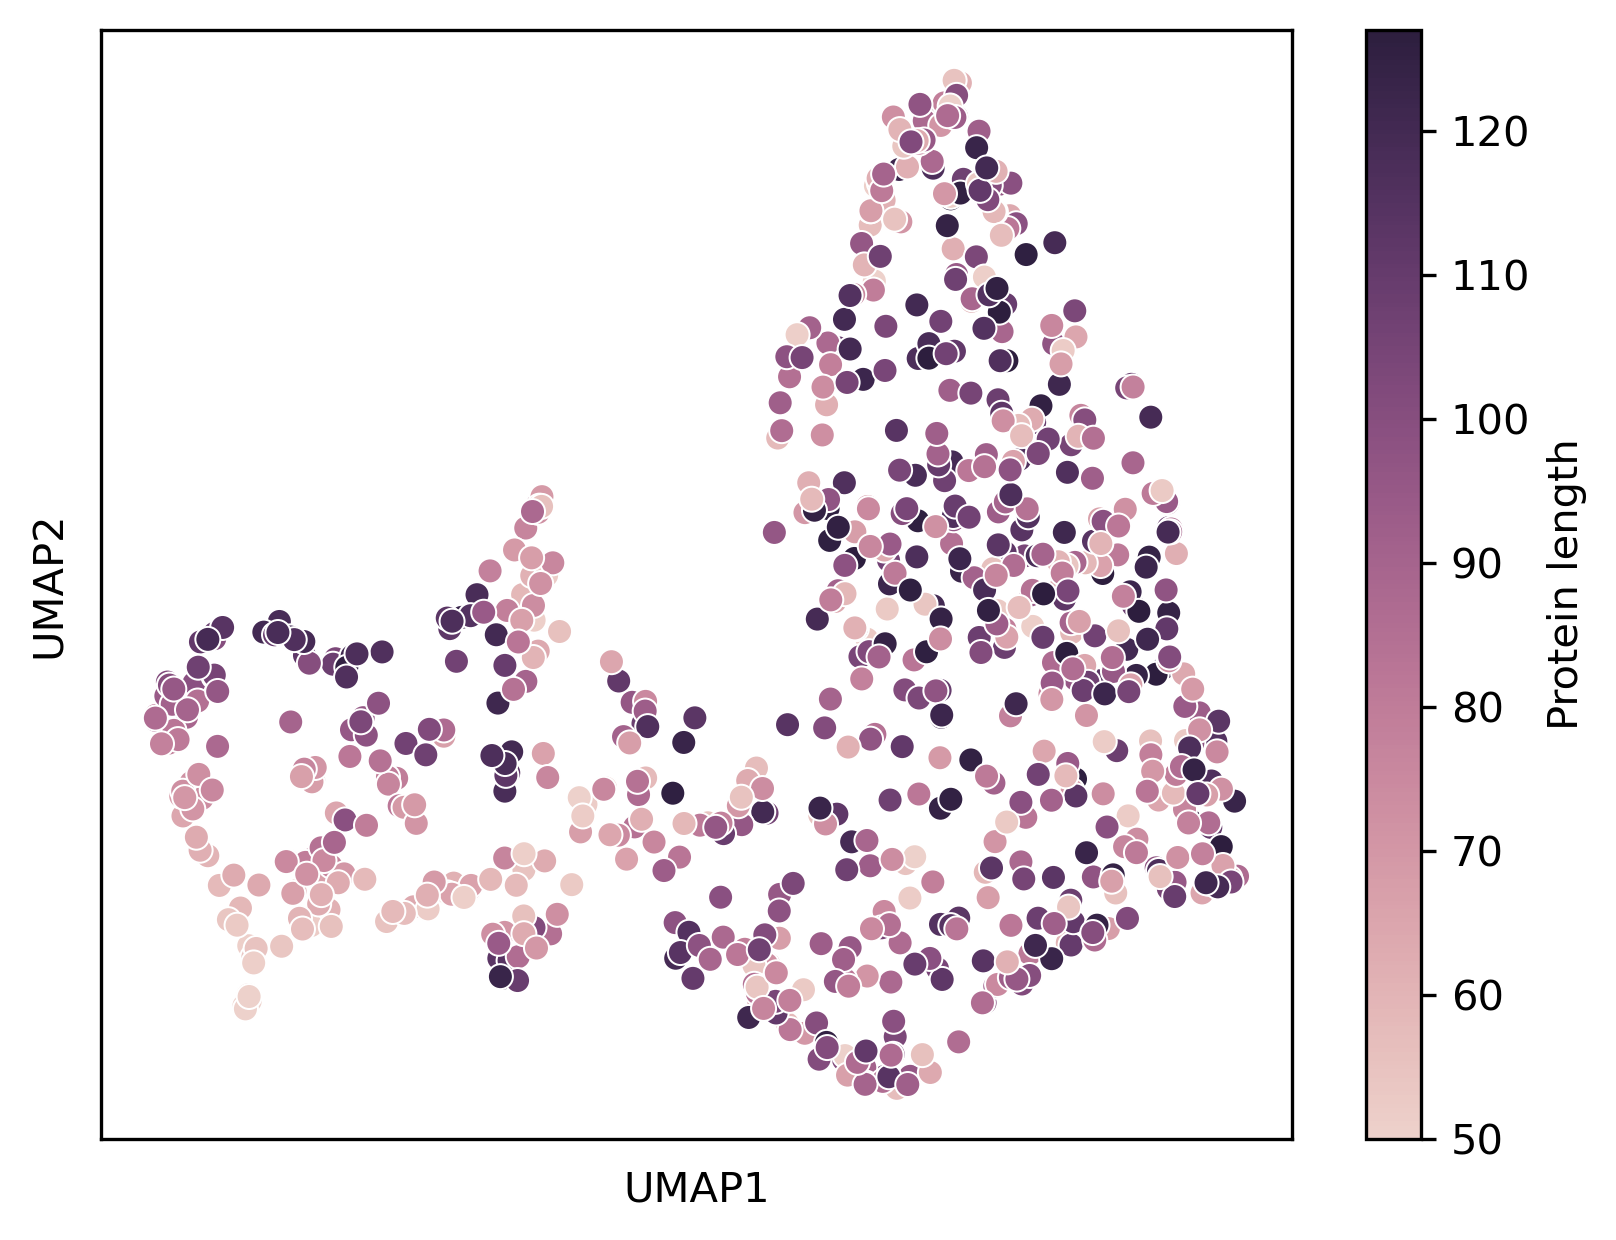

In [8]:
fig, ax = plt.subplots(dpi=300)
norm = plt.Normalize(sampled_git_umap['length_int'].min(), sampled_git_umap['length_int'].max())
sns.scatterplot(
    data=sampled_git_umap,
    x='UMAP1',
    y='UMAP2',
    hue='length_int',
    hue_norm=norm,
    palette=sns.cubehelix_palette(as_cmap=True),
)
sm = plt.cm.ScalarMappable(cmap=sns.cubehelix_palette(as_cmap=True), norm=norm)
sm.set_array([])
ax.get_legend().remove()
fig.colorbar(sm, ax=ax, label=r"Protein length")

ax.set(
    xticks=[], yticks=[],
)
fig.savefig(os.path.join(PLOT_DIR, "sampled_git_umap_by_length.pdf"), bbox_inches='tight')
fig.show()

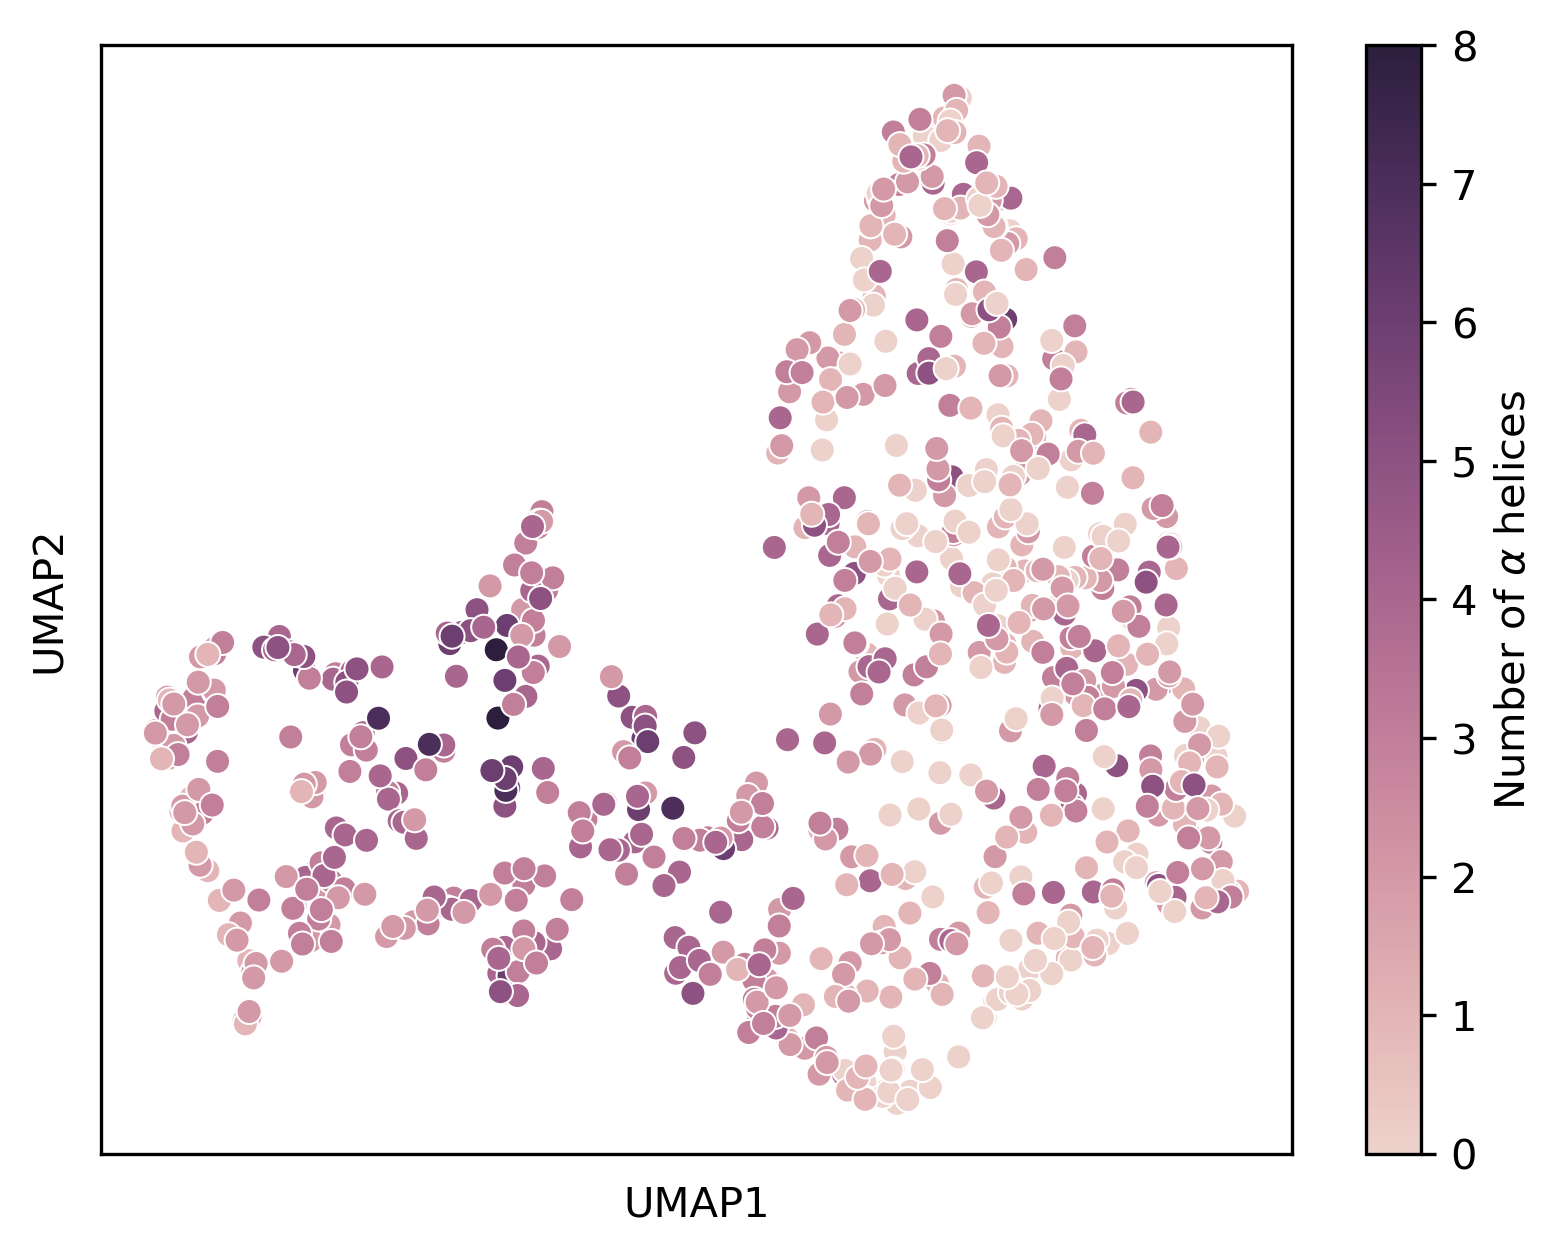

In [9]:
fig, ax = plt.subplots(dpi=300)
norm = plt.Normalize(sampled_git_umap['alpha_counts'].min(), sampled_git_umap['alpha_counts'].max())
sns.scatterplot(
    data=sampled_git_umap,
    x='UMAP1',
    y='UMAP2',
    hue='alpha_counts',
    hue_norm=norm,
    palette=sns.cubehelix_palette(as_cmap=True),
)
sm = plt.cm.ScalarMappable(cmap=sns.cubehelix_palette(as_cmap=True), norm=norm)
sm.set_array([])
ax.get_legend().remove()
fig.colorbar(sm, ax=ax, label=r"Number of $\alpha$ helices")

ax.set(
    xticks=[], yticks=[],
)
fig.savefig(os.path.join(PLOT_DIR, "sampled_git_umap_by_alpha.pdf"), bbox_inches='tight')
fig.show()

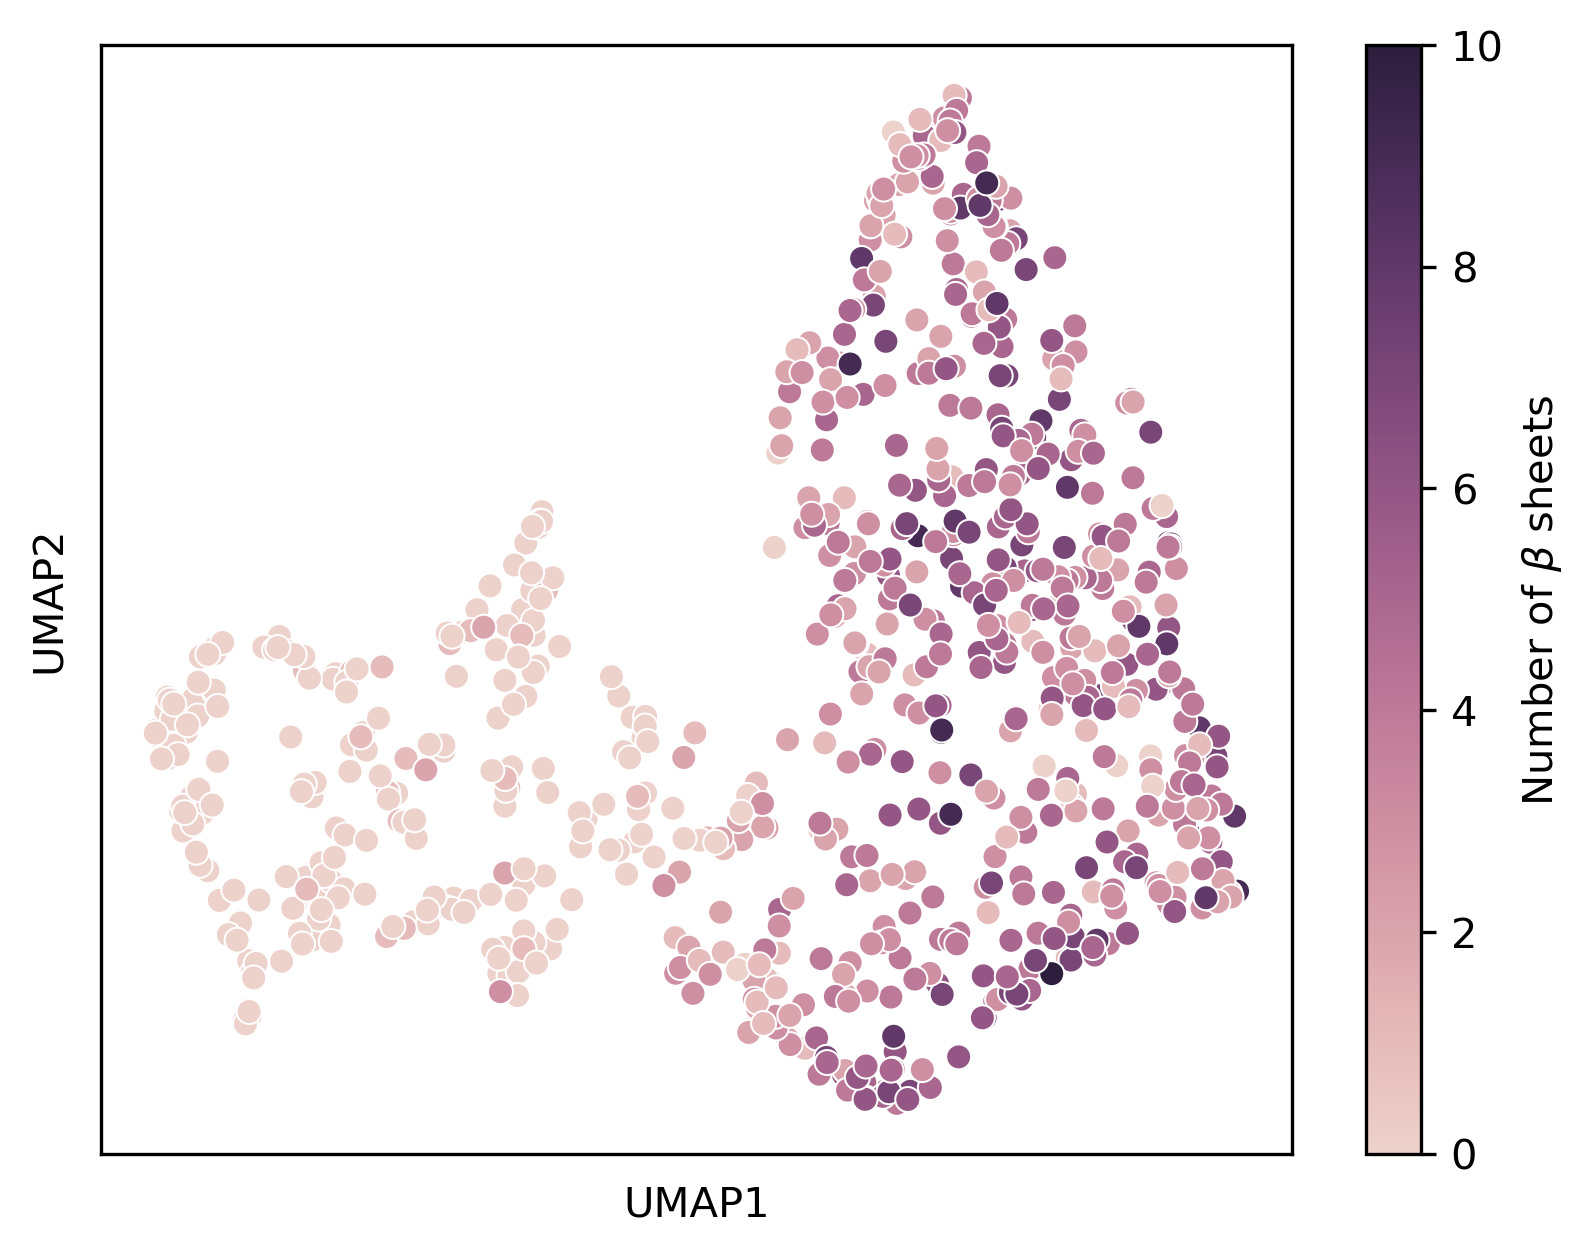

In [10]:
fig, ax = plt.subplots(dpi=300)
norm = plt.Normalize(sampled_git_umap['beta_counts'].min(), sampled_git_umap['beta_counts'].max())
sns.scatterplot(
    data=sampled_git_umap,
    x='UMAP1',
    y='UMAP2',
    hue='beta_counts',
    hue_norm=norm,
    palette=sns.cubehelix_palette(as_cmap=True),
)
sm = plt.cm.ScalarMappable(cmap=sns.cubehelix_palette(as_cmap=True), norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, label=r"Number of $\beta$ sheets")
ax.get_legend().remove()

ax.set(
    xticks=[], yticks=[],
)
fig.savefig(os.path.join(PLOT_DIR, "sampled_git_umap_by_beta.pdf"), bbox_inches='tight')
fig.show()

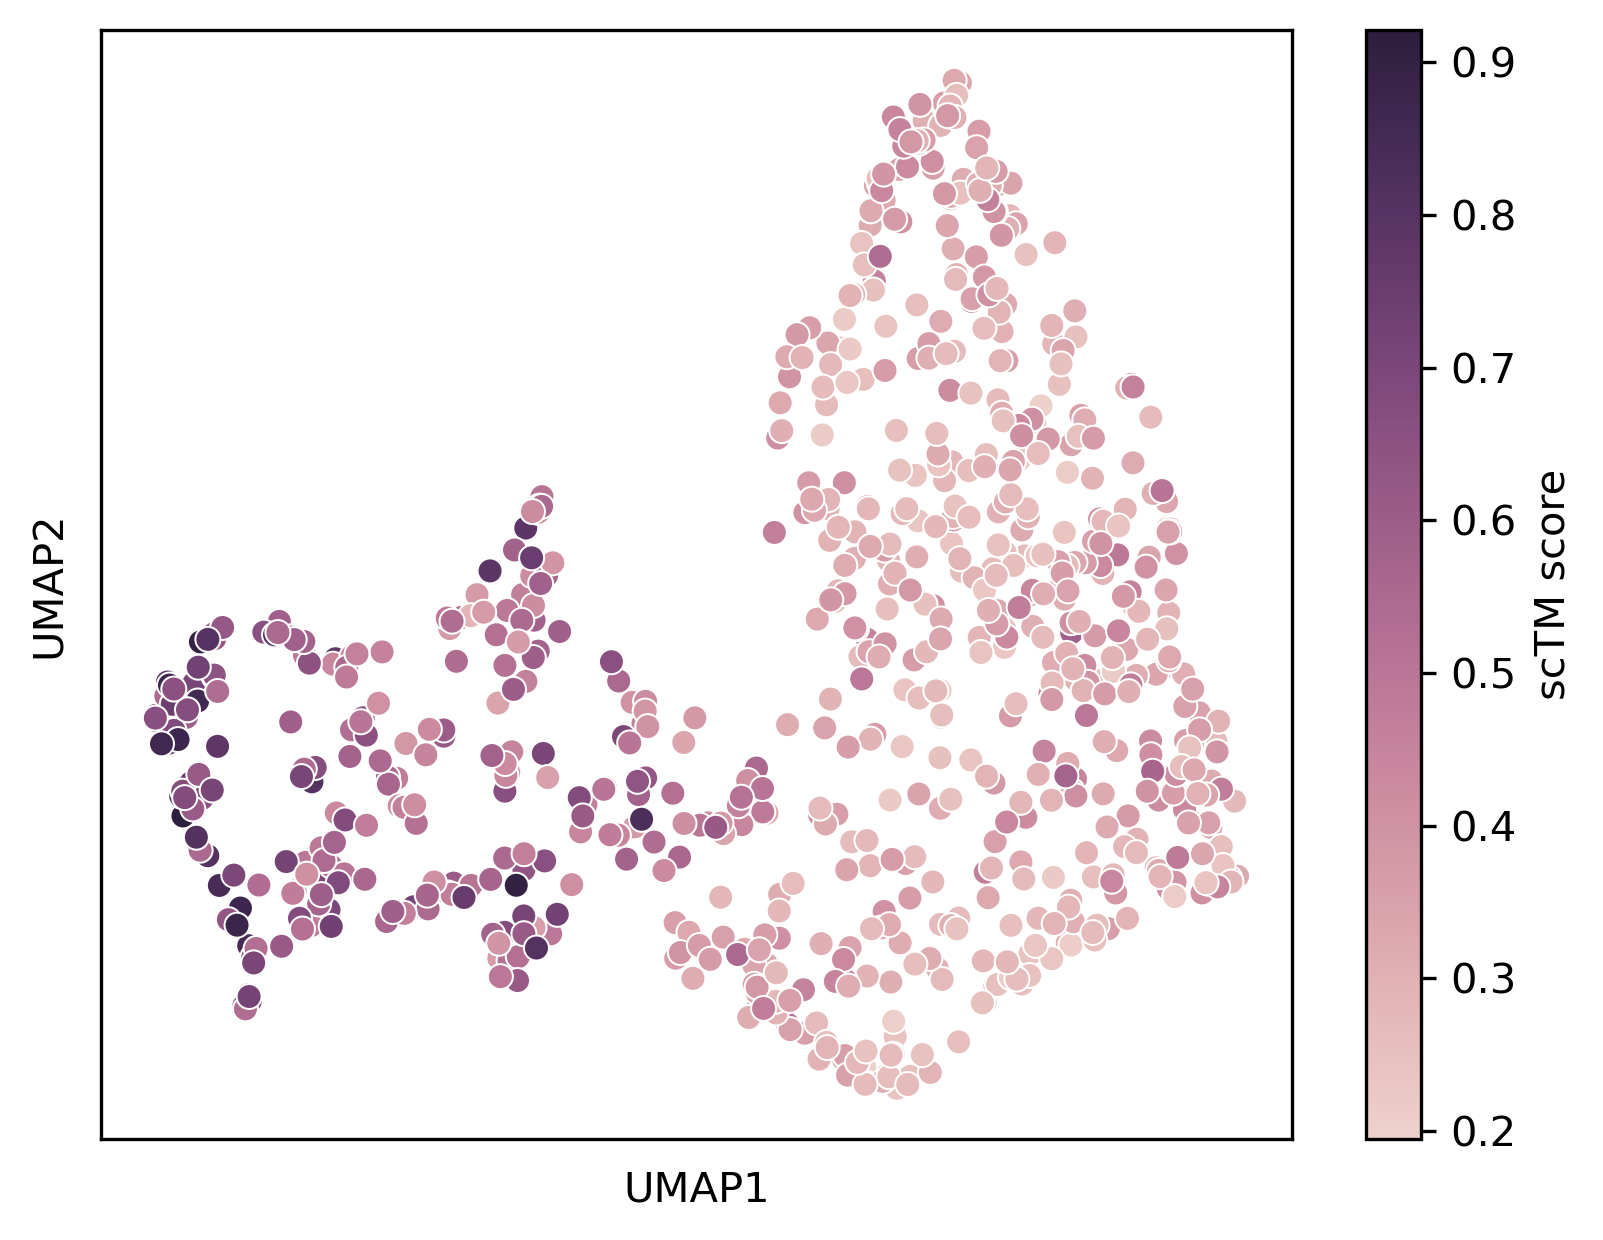

In [11]:
fig, ax = plt.subplots(dpi=300)
norm = plt.Normalize(sampled_git_umap['scTM'].min(), sampled_git_umap['scTM'].max())
sns.scatterplot(
    data=sampled_git_umap,
    x='UMAP1',
    y='UMAP2',
    hue='scTM',
    hue_norm=norm,
    palette=sns.cubehelix_palette(as_cmap=True),
    ax=ax,
)
sm = plt.cm.ScalarMappable(cmap=sns.cubehelix_palette(as_cmap=True), norm=norm)
sm.set_array([])
ax.get_legend().remove()
fig.colorbar(sm, ax=ax, label="scTM score")

ax.set(
    xticks=[], yticks=[],
)
fig.savefig(os.path.join(PLOT_DIR, "sampled_git_umap_by_sctm.pdf"), bbox_inches='tight')
fig.show()

# Combined plots

In [12]:
combined_metadata_df = pd.concat([sampled_metadata_df, test_metadata_df], axis=0, join='inner')
combined_metadata_df

,alpha_counts,beta_counts
generated_202,1,3
generated_414,2,2
generated_309,4,0
generated_529,0,6
generated_194,3,2
...,...,...
test_1jb3A00,3,6
test_1dgjA01,1,1
test_4ak2A01,0,5
test_4hj1C03,0,8


In [13]:
combined_umap = umap_embed(pd.concat([test_git_values, sampled_git_values]))
combined_umap.head()

,UMAP1,UMAP2
test_4liqE05,11.419374,3.813149
test_4it4A02,4.466052,8.709891
test_2ma6A00,10.181295,3.503077
test_4xvhA01,10.108700,1.616123
test_1oxjA02,5.099641,8.601936


In [14]:
combined_umap['source'] = [i.split('_')[0] for i in combined_umap.index]
combined_umap = combined_umap.join(combined_metadata_df, how='inner')
combined_umap

,UMAP1,UMAP2,source,alpha_counts,beta_counts
test_4liqE05,11.419374,3.813149,test,0,5
test_4it4A02,4.466052,8.709891,test,3,0
test_2ma6A00,10.181295,3.503077,test,1,0
test_4xvhA01,10.108700,1.616123,test,0,4
test_1oxjA02,5.099641,8.601936,test,5,0
...,...,...,...,...,...
generated_412,4.805202,6.143592,generated,4,2
generated_469,3.510618,8.002620,generated,4,0
generated_352,10.708916,5.963565,generated,1,5
generated_403,6.146467,7.955847,generated,2,3


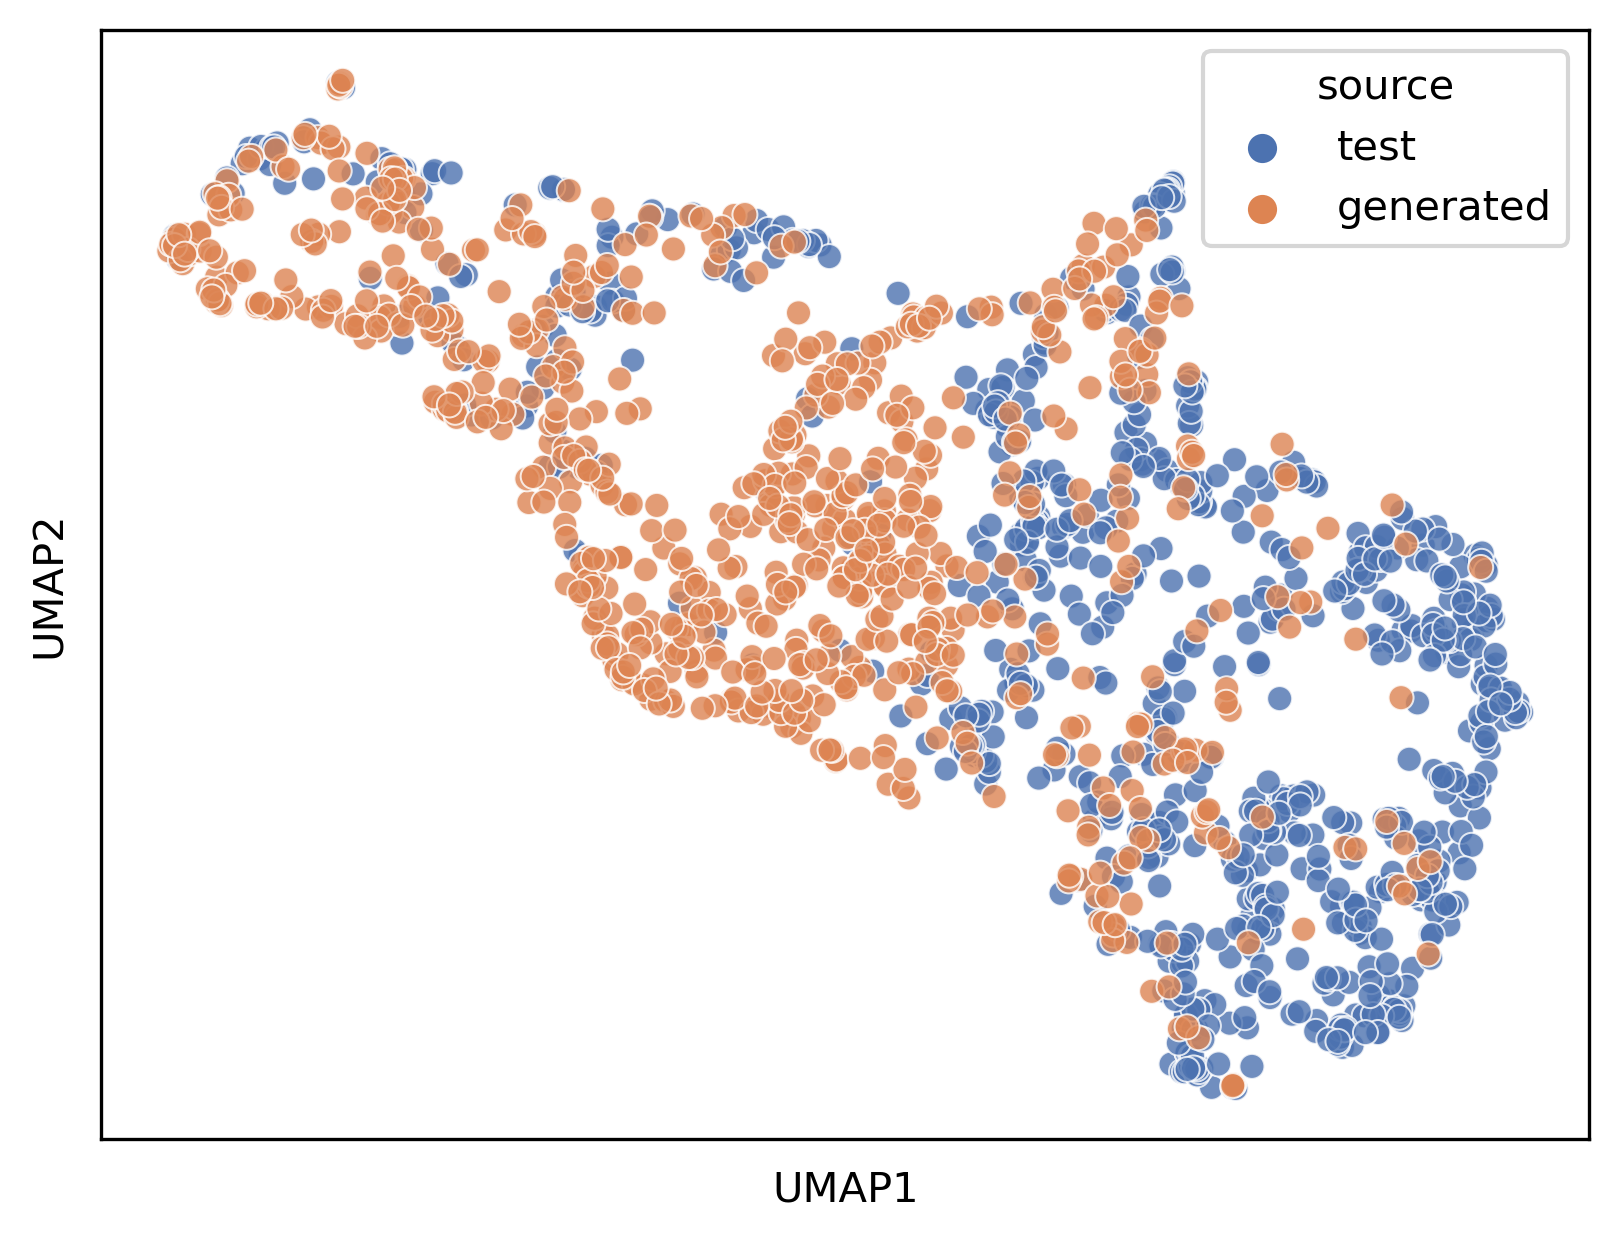

In [15]:
fig, ax = plt.subplots(dpi=300)
sns.scatterplot(
    data=combined_umap, x='UMAP1', y='UMAP2',
    hue="source",
    palette=sns.color_palette("deep", n_colors=2),
    alpha=0.8,
    ax=ax,
)
ax.set(
    xticks=[], yticks=[],
)
fig.savefig(os.path.join(PLOT_DIR, "combined_git_umap_by_source.pdf"), bbox_inches='tight')
fig.show()

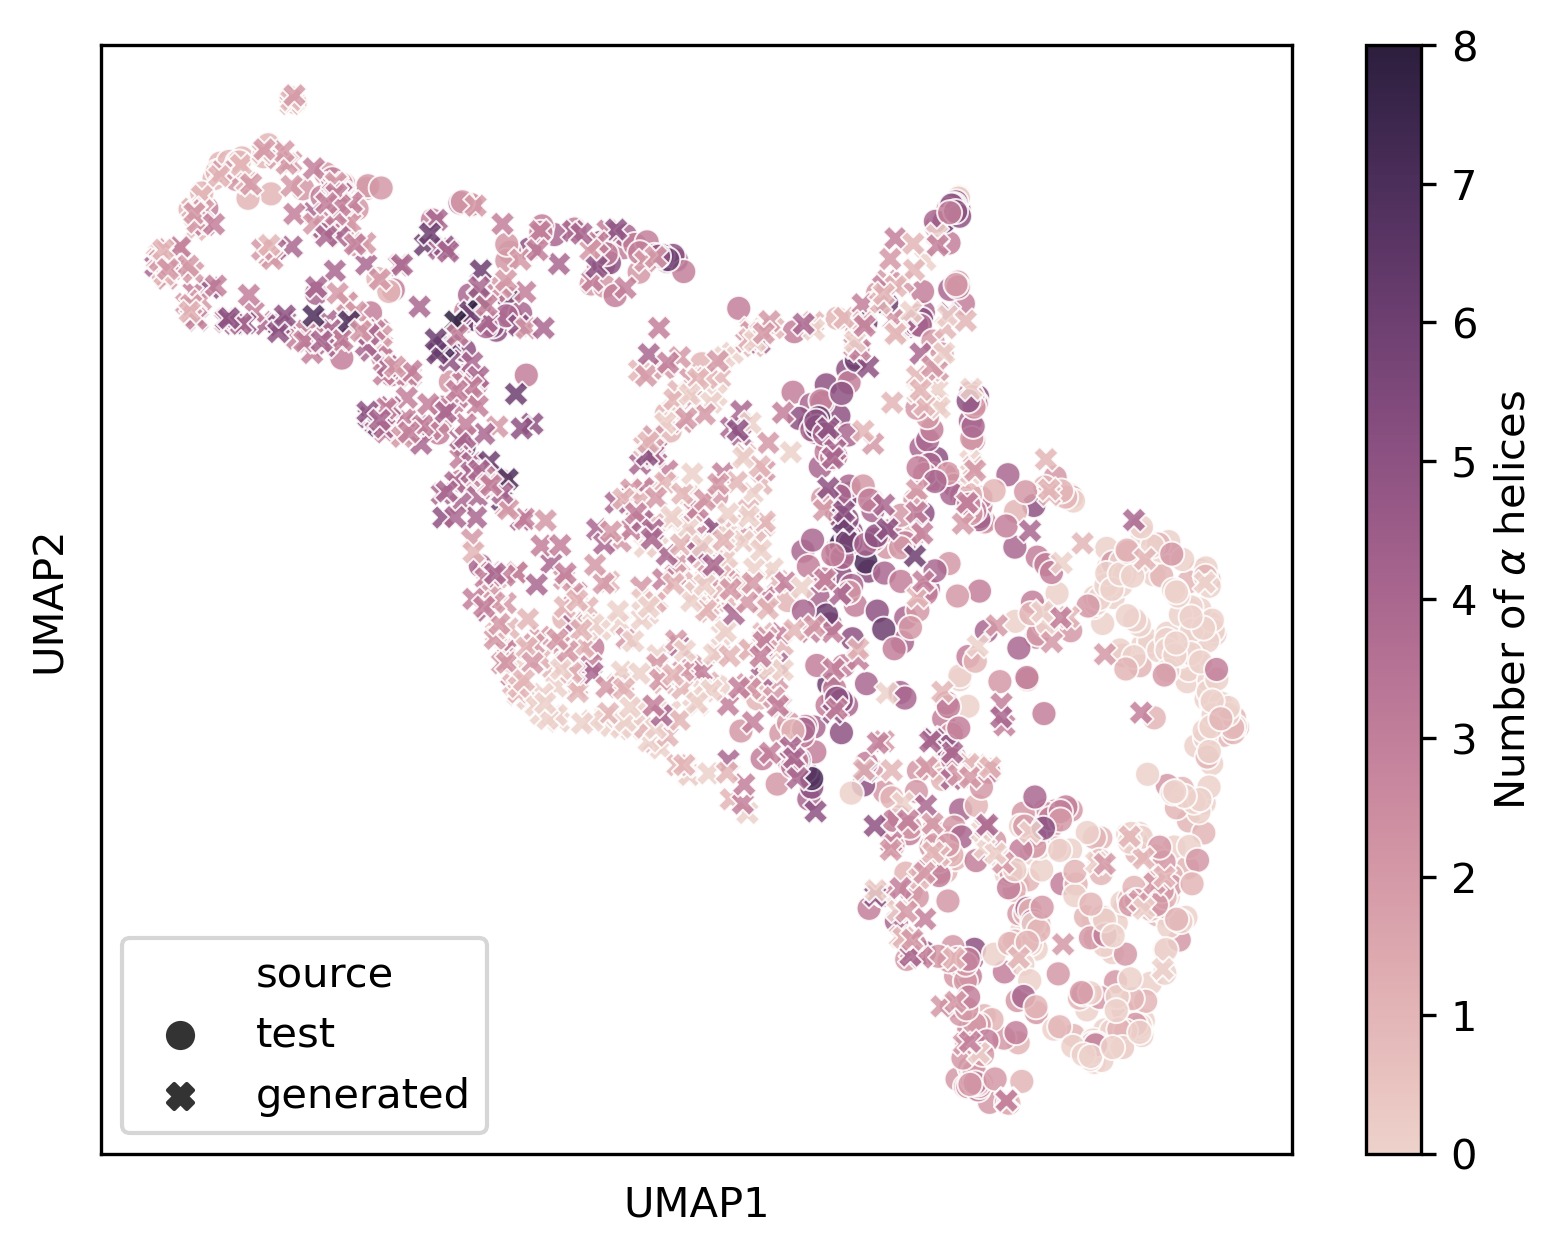

In [16]:
fig, ax = plt.subplots(dpi=300)
norm = plt.Normalize(combined_umap['alpha_counts'].min(), combined_umap['alpha_counts'].max())
sns.scatterplot(
    data=combined_umap, x='UMAP1', y='UMAP2',
    hue='alpha_counts',
    hue_norm=norm,
    style="source",
    palette=sns.cubehelix_palette(as_cmap=True),
    alpha=0.85,
    ax=ax,
)
# Segned only for source
h, l = ax.get_legend_handles_labels()
ax.legend(h[-3:], l[-3:], loc='lower left')
# Set colorbar
sm = plt.cm.ScalarMappable(cmap=sns.cubehelix_palette(as_cmap=True), norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, label=r"Number of $\alpha$ helices")
ax.set(xticks=[], yticks=[])
fig.savefig(os.path.join(PLOT_DIR, "combined_git_umap_by_alpha.pdf"), bbox_inches='tight')
fig.show()

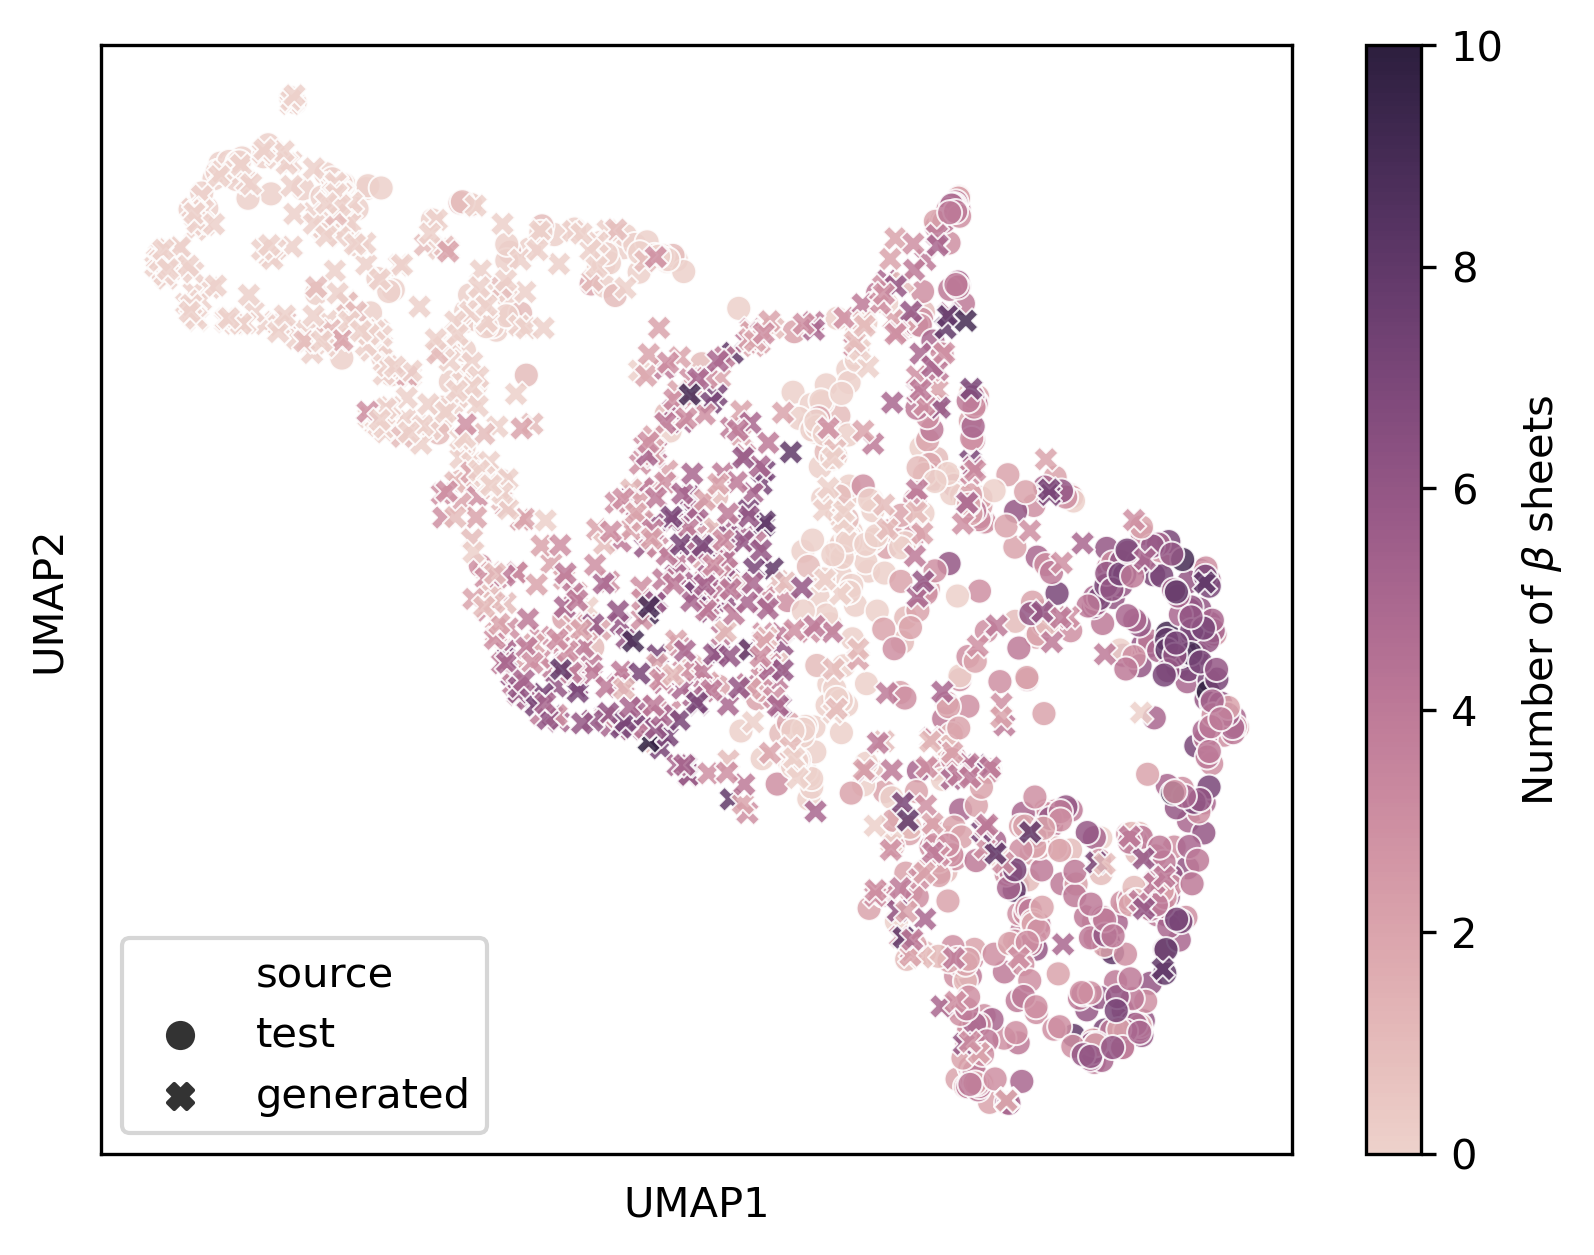

In [17]:
fig, ax = plt.subplots(dpi=300)
norm = plt.Normalize(combined_umap['beta_counts'].min(), combined_umap['beta_counts'].max())
sns.scatterplot(
    data=combined_umap, x='UMAP1', y='UMAP2',
    hue='beta_counts',
    hue_norm=norm,
    style="source",
    palette=sns.cubehelix_palette(as_cmap=True),
    alpha=0.85,
    ax=ax,
)
# Segned only for source
h, l = ax.get_legend_handles_labels()
ax.legend(h[-3:], l[-3:], loc='lower left')
# Set colorbar
sm = plt.cm.ScalarMappable(cmap=sns.cubehelix_palette(as_cmap=True), norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, label=r"Number of $\beta$ sheets")
ax.set(xticks=[], yticks=[])
fig.savefig(os.path.join(PLOT_DIR, "combined_git_umap_by_beta.pdf"), bbox_inches='tight')
fig.show()